# Automatic Category Suggestion for Wikimedia Commons

**Full pipeline — no scipy/sklearn dependencies**

```
Image + Metadata
      |
   CLIP ViT-B/32
      |
  kNN  Text  Supervised  Metadata
  FAISS Prototype  Head   Scorer
      |
   Calibrated Fusion (pure NumPy logistic)
      |
   Hierarchy DAG post-processing
      |
   Top-k Suggestions
```


In [ ]:
# ============================================================
# ENVIRONMENT CHECK  (works on local myenv AND Kaggle/Colab)
# ============================================================
import sys, os
print('Python   :', sys.executable)
print('Version  :', sys.version.split()[0])

IS_KAGGLE = os.path.exists('/kaggle') or 'KAGGLE_KERNEL_RUN_TYPE' in os.environ
IS_COLAB  = 'google.colab' in sys.modules
IS_LOCAL  = any(k in sys.executable.lower() for k in ['myenv', 'mega'])

if IS_KAGGLE:
    print('Environment: Kaggle')
elif IS_COLAB:
    print('Environment: Google Colab')
elif IS_LOCAL:
    print('Environment: local myenv virtual environment')
else:
    print('WARNING: unrecognized environment - make sure the right kernel/venv is selected.')

In [ ]:
# ============================================================
# Dependencies - install anything missing (Kaggle/Colab friendly)
# faiss-cpu is NOT preinstalled on Kaggle; torch/transformers usually are.
# The CLIP helper in Step 3 supports both transformers 4.x and 5.x.
# ============================================================
import importlib, subprocess, sys
def _ensure(mod, pip_name=None):
    try:
        importlib.import_module(mod)
    except ImportError:
        name = pip_name or mod
        print(f'Installing {name} ...')
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', name], check=True)
for mod, pip_name in [('torch', 'torch'), ('transformers', 'transformers'),
                      ('faiss', 'faiss-cpu'), ('PIL', 'pillow'),
                      ('tqdm', 'tqdm'), ('matplotlib', 'matplotlib'),
                      ('sentencepiece', 'sentencepiece'), ('google.protobuf', 'protobuf')]:
    _ensure(mod, pip_name)
print('Dependencies ready.')

In [ ]:
# ============================================================
# Step 0 - Imports  (no scipy / scikit-learn)
# ============================================================
import os, json, time, pickle, hashlib, warnings, requests, re, random, statistics
import numpy as np
import matplotlib.pyplot as plt
from io import BytesIO
from pathlib import Path
from datetime import datetime
from collections import defaultdict, Counter
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from PIL import Image
from transformers import CLIPModel, CLIPProcessor
import faiss

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')
if DEVICE == 'cuda':
    print('GPU   :', torch.cuda.get_device_name(0))
    torch.backends.cudnn.benchmark = True

# GPU-aware throughput knobs (smaller on CPU to stay within memory).
IMG_BATCH        = 64 if DEVICE == 'cuda' else 32    # images per CLIP forward
TXT_BATCH        = 256 if DEVICE == 'cuda' else 128   # texts per CLIP forward
DOWNLOAD_WORKERS = 8      # parallel image downloads (Wikimedia-friendly)

BASE_DIR = Path('.')
DATA_DIR = BASE_DIR / 'data'
IMG_DIR  = DATA_DIR / 'images'
EMB_DIR  = BASE_DIR / 'embeddings'
MDL_DIR  = BASE_DIR / 'models'
RES_DIR  = BASE_DIR / 'results'
for d in [DATA_DIR, IMG_DIR, EMB_DIR, MDL_DIR, RES_DIR]:
    d.mkdir(parents=True, exist_ok=True)
print('Directories ready.')

In [3]:
# ============================================================
# Step 0b — Pure-NumPy / PyTorch helper classes
#   Replacing sklearn: MultiLabelBinarizer, LogisticRegression,
#                       average_precision_score
# ============================================================

# ── MultiLabelBinarizer ──────────────────────────────────────────────────────
class MultiLabelBinarizer:
    """Convert lists of category names to binary (0/1) vectors."""
    def __init__(self, classes=None):
        self.classes_ = list(classes) if classes is not None else []
        self._cat2idx = {c: i for i, c in enumerate(self.classes_)}

    def fit(self, y):
        if not self.classes_:
            all_cats = sorted({c for row in y for c in row})
            self.classes_  = all_cats
            self._cat2idx  = {c: i for i, c in enumerate(all_cats)}
        return self

    def transform(self, y) -> np.ndarray:
        out = np.zeros((len(y), len(self.classes_)), dtype='float32')
        for i, cats in enumerate(y):
            for c in cats:
                if c in self._cat2idx:
                    out[i, self._cat2idx[c]] = 1.0
        return out


# ── Logistic Regression (pure NumPy, L-BFGS-style via gradient descent) ─────
class LogisticRegression:
    """
    Binary logistic regression trained with mini-batch gradient descent.
    Drop-in for sklearn's LogisticRegression for the fusion use-case.
    """
    def __init__(self, lr=0.05, n_iter=300, C=1.0, tol=1e-5):
        self.lr, self.n_iter, self.C, self.tol = lr, n_iter, C, tol
        self.coef_ = None
        self.intercept_ = None

    def _sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -50, 50)))

    def fit(self, X: np.ndarray, y: np.ndarray):
        n, d  = X.shape
        w     = np.zeros(d, dtype='float64')
        b     = 0.0
        prev_loss = float('inf')
        for it in range(self.n_iter):
            p    = self._sigmoid(X @ w + b)
            err  = p - y
            grad_w = (X.T @ err) / n + w / self.C
            grad_b = err.mean()
            w -= self.lr * grad_w
            b -= self.lr * grad_b
            loss = (-y * np.log(p + 1e-9) - (1 - y) * np.log(1 - p + 1e-9)).mean()
            if abs(prev_loss - loss) < self.tol:
                break
            prev_loss = loss
        self.coef_      = w.reshape(1, -1)
        self.intercept_ = np.array([b])
        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        p = self._sigmoid(X @ self.coef_[0] + self.intercept_[0])
        return np.column_stack([1 - p, p])


# ── Average Precision Score (pure NumPy) ─────────────────────────────────────
def average_precision_score(y_true: np.ndarray, y_score: np.ndarray) -> float:
    """Compute AP for a single binary label vector."""
    sorted_idx = np.argsort(-y_score)
    y_sorted   = y_true[sorted_idx]
    n_pos      = y_true.sum()
    if n_pos == 0:
        return 0.0
    cumtp   = np.cumsum(y_sorted)
    ranks   = np.arange(1, len(y_sorted) + 1)
    prec    = cumtp / ranks
    ap      = (prec * y_sorted).sum() / n_pos
    return float(ap)


print('Custom MultiLabelBinarizer, LogisticRegression, AP score ready (no scipy/sklearn).')


Custom MultiLabelBinarizer, LogisticRegression, AP score ready (no scipy/sklearn).


## Step 1 — Data Collection from Wikimedia Commons API


In [ ]:
# ============================================================
# Step 1 - Data Collection from Wikimedia Commons API
# ============================================================
COMMONS_API = 'https://commons.wikimedia.org/w/api.php'
HEADERS     = {'User-Agent': 'WikiCommonsCategorySuggester/1.0 (educational hackathon project)'}

# ~60 content categories across the four families the problem statement asks for
# (objects, scenes, events, abstract/cultural). Scale these freely on a GPU box.
TARGET_CATEGORIES = [
    # Animals
    'Cats', 'Dogs', 'Birds', 'Butterflies', 'Horses', 'Fishes', 'Insects',
    'Snakes', 'Frogs', 'Spiders', 'Bees', 'Elephants', 'Lions', 'Tigers',
    'Bears', 'Deer', 'Owls', 'Ducks', 'Penguins', 'Turtles', 'Sheep', 'Cattle',
    # Plants / nature objects
    'Flowers', 'Trees', 'Mushrooms', 'Cacti', 'Ferns', 'Fruits', 'Vegetables',
    # Vehicles
    'Automobiles', 'Bicycles', 'Ships', 'Aircraft', 'Trains', 'Buses',
    'Motorcycles', 'Trucks', 'Helicopters', 'Boats', 'Tractors', 'Trams',
    # Natural scenes
    'Beaches', 'Mountains', 'Forests', 'Deserts', 'Waterfalls', 'Lakes',
    'Rivers', 'Caves', 'Glaciers', 'Volcanoes', 'Islands', 'Canyons',
    # Urban / architecture
    'Cityscapes', 'Bridges', 'Churches', 'Temples', 'Mosques', 'Castles',
    'Lighthouses', 'Skyscrapers', 'Stadiums', 'Windmills', 'Towers', 'Palaces',
    'Fountains', 'Gardens', 'Museums', 'Libraries', 'Railway stations',
    # Events / activities
    'Festivals', 'Parades', 'Weddings', 'Concerts', 'Carnivals', 'Markets',
    # Abstract / cultural
    'Maps', 'Diagrams', 'Flags', 'Logos', 'Coats of arms', 'Paintings',
    'Sculptures', 'Postage stamps', 'Banknotes', 'Coins', 'Clocks', 'Books',
    'Posters', 'Drawings', 'Statues',
    # Everyday objects
    'Bread', 'Cheese', 'Wine', 'Coffee', 'Cakes', 'Lamps', 'Chairs',
    'Cameras', 'Guitars', 'Shoes', 'Hats', 'Bottles', 'Umbrellas',
]

IMAGES_PER_CATEGORY = 200          # seed files pulled per target category (cmlimit <= 500)
THUMBNAIL_SIZE      = 224

# Backup text filter for any *non-hidden* tracking/license categories that slip
# past the API's `clshow=!hidden` flag. The PDF (section 2) requires dropping
# licence templates, maintenance/backlog and hidden process categories.
MAINTENANCE_PATTERNS = [
    'uploaded with', 'files from', 'media needing', 'possible copyright',
    'license review', 'wikimedia commons', 'quality images', 'valued images',
    'featured pictures', 'self-published work', 'creative commons',
    'public domain', 'pages with', 'images with', 'files lacking', 'check categories',
    # licence tags
    'cc-by', 'cc-sa', 'cc-zero', 'cc0', 'gfdl', 'pd-', 'attribution',
    'share-alike', 'share alike', 'licence', 'license',
    # structured-data / wikidata / geo maintenance
    'without wikidata', 'wikidata item', 'with coordinates', 'coordinates missing',
    'sdc', 'location of creation', 'media missing', 'media lacking',
    'media without', 'media supported', 'media with', 'taken with', 'scanned with',
    'extracted from', 'flickr', 'files by', 'photographs by',
]

def is_maintenance_category(cat_name: str) -> bool:
    lower = cat_name.lower()
    return any(p in lower for p in MAINTENANCE_PATTERNS)

# ---- robust Action-API session -------------------------------------------
# A persistent Session (connection reuse) + maxlag is essential: plain
# requests.get opens a new connection each call and Wikimedia throttles that
# after ~5 rapid requests, which silently truncated collection to a handful of
# categories. This routes every API call through one retrying session.
from requests.adapters import HTTPAdapter
try:
    from urllib3.util.retry import Retry
except Exception:
    from requests.packages.urllib3.util.retry import Retry

def _make_api_session():
    s = requests.Session()
    retry = Retry(total=5, connect=5, read=5, backoff_factor=1.0,
                  status_forcelist=[429, 500, 502, 503, 504],
                  allowed_methods=['GET'], respect_retry_after_header=True)
    ad = HTTPAdapter(max_retries=retry, pool_connections=4, pool_maxsize=4)
    s.mount('https://', ad); s.mount('http://', ad)
    s.headers.update(HEADERS)
    return s

API_SESSION = _make_api_session()

def _api_get(params):
    params = {**params, 'format': 'json', 'maxlag': 5}
    for attempt in range(4):
        try:
            r = API_SESSION.get(COMMONS_API, params=params, timeout=30)
            r.raise_for_status()
            d = r.json()
            if isinstance(d, dict) and d.get('error', {}).get('code') == 'maxlag':
                time.sleep(2 * (attempt + 1)); continue
            return d
        except Exception:
            time.sleep(1.5 * (attempt + 1))
    return {}

def _list_members(cat, cmtype, limit):
    out, cont = [], None
    while len(out) < limit:
        p = {'action': 'query', 'list': 'categorymembers',
             'cmtitle': f'Category:{cat}', 'cmtype': cmtype,
             'cmlimit': min(500, limit - len(out))}
        if cont:
            p['cmcontinue'] = cont
        d = _api_get(p)
        out += d.get('query', {}).get('categorymembers', [])
        cont = d.get('continue', {}).get('cmcontinue')
        if not cont:
            break
    return out[:limit]

def fetch_category_members(category, limit=IMAGES_PER_CATEGORY, max_visits=40):
    """Breadth-first over the category tree collecting file members. Many broad
    Commons categories (Birds, Fishes, Mountains, ...) keep their files in
    subcategories and have zero direct files, so a flat query returns almost
    nothing; BFS descends into subcategories until `limit` files are gathered."""
    files, seen = [], set()
    queue, visited, visits = [category], {category}, 0
    while queue and len(files) < limit and visits < max_visits:
        cat = queue.pop(0); visits += 1
        for m in _list_members(cat, 'file', limit - len(files)):
            if m['title'] not in seen:
                seen.add(m['title']); files.append(m)
        if len(files) < limit:
            for sc in _list_members(cat, 'subcat', 30):
                nm = sc['title'].replace('Category:', '').strip()
                if nm not in visited and not is_maintenance_category(nm):
                    visited.add(nm); queue.append(nm)
        time.sleep(0.05)
    return files[:limit]

def fetch_file_info(titles: list) -> dict:
    # <=50 titles/request; clshow='!hidden' returns only content categories.
    pages = {}
    for i in range(0, len(titles), 50):
        chunk = titles[i:i + 50]
        if not chunk:
            continue
        d = _api_get({'action': 'query', 'titles': '|'.join(chunk),
                      'prop': 'imageinfo|categories',
                      'iiprop': 'url|extmetadata|timestamp',
                      'iiurlwidth': THUMBNAIL_SIZE, 'clshow': '!hidden',
                      'cllimit': 50})
        pages.update(d.get('query', {}).get('pages', {}))
    return pages

def collect_dataset(save_path: Path = DATA_DIR / 'raw_metadata_v2.json') -> list:
    if save_path.exists():
        print(f'Loading cached dataset from {save_path}')
        with open(save_path, 'r', encoding='utf-8') as f:
            return json.load(f)

    records, zero_cats = [], 0
    for cat in tqdm(TARGET_CATEGORIES, desc='Fetching categories'):
        members = fetch_category_members(cat, limit=IMAGES_PER_CATEGORY)
        if not members:
            zero_cats += 1
        pages = fetch_file_info([m['title'] for m in members])
        for pid, page in pages.items():
            if 'imageinfo' not in page:
                continue
            info = page['imageinfo'][0]
            raw_cats = [c['title'].replace('Category:', '').strip()
                        for c in page.get('categories', [])]
            clean_cats = [c for c in raw_cats if not is_maintenance_category(c)]
            if not clean_cats:
                continue
            ext = info.get('extmetadata', {})
            records.append({
                'page_id':     pid,
                'title':       ext.get('ObjectName', {}).get('value',
                               page.get('title', '').replace('File:', '')),
                'description': ext.get('ImageDescription', {}).get('value', ''),
                'timestamp':   ext.get('DateTimeOriginal', {}).get('value',
                               info.get('timestamp', '')),
                'thumb_url':   info.get('thumburl', ''),
                'categories':  clean_cats,
                'source_cat':  cat,
            })

    if zero_cats:
        print(f'Note: {zero_cats}/{len(TARGET_CATEGORIES)} seed categories yielded no files.')
    with open(save_path, 'w', encoding='utf-8') as f:
        json.dump(records, f, ensure_ascii=False, indent=2)
    print(f'Collected {len(records)} records from {len(TARGET_CATEGORIES)} seed categories.')
    return records


records = collect_dataset()
print(f'Total records: {len(records)}')

## Step 2 — Preprocessing: Dedup, Filter, Temporal Split


In [ ]:
# ============================================================
# Step 2 — Preprocessing
# ============================================================
MIN_CATEGORY_IMAGES = 10
TEST_RATIO          = 0.20

def deduplicate(records):
    seen, unique = set(), []
    for r in records:
        url = r.get('thumb_url', '')
        if url and url not in seen:
            seen.add(url); unique.append(r)
    print(f'After dedup: {len(unique)} (removed {len(records)-len(unique)})')
    return unique

def filter_categories(records, min_count=MIN_CATEGORY_IMAGES):
    cat_count  = Counter(c for r in records for c in r['categories'])
    valid_cats = {c for c, n in cat_count.items() if n >= min_count}
    print(f'Categories: {len(cat_count)} total, {len(valid_cats)} after freq filter (>={min_count})')
    filtered = []
    for r in records:
        cats = [c for c in r['categories'] if c in valid_cats]
        if cats:
            filtered.append({**r, 'categories': cats})
    print(f'Records: {len(records)} -> {len(filtered)}')
    return filtered, sorted(valid_cats)

def parse_ts(ts):
    for fmt in ('%Y-%m-%dT%H:%M:%SZ', '%Y:%m:%d %H:%M:%S', '%Y-%m-%d'):
        try: return datetime.strptime(ts[:19], fmt)
        except Exception: pass
    return datetime(2000, 1, 1)

def temporal_split(records, test_ratio=TEST_RATIO):
    s      = sorted(records, key=lambda r: parse_ts(r.get('timestamp', '')))
    n_test = max(1, int(len(s) * test_ratio))
    return s[:-n_test], s[-n_test:]


records_dedup            = deduplicate(records)
records_filt, ALL_CATS   = filter_categories(records_dedup)
train_records, test_records = temporal_split(records_filt)

print(f'Train: {len(train_records)}  |  Test: {len(test_records)}')
print(f'Category vocabulary: {len(ALL_CATS)}')

with open(DATA_DIR / 'category_vocab.json', 'w', encoding='utf-8') as f:
    json.dump(ALL_CATS, f, ensure_ascii=False, indent=2)

MLB = MultiLabelBinarizer(classes=ALL_CATS)
MLB.fit([ALL_CATS])

# Frequency distribution
freqs = sorted(Counter(c for r in records_filt for c in r['categories']).values(), reverse=True)
plt.figure(figsize=(9, 3))
plt.plot(freqs, color='#4C72B0')
plt.yscale('log'); plt.xscale('log')
plt.xlabel('Category rank'); plt.ylabel('Count (log)')
plt.title('Category Frequency — Long-tail Distribution')
plt.tight_layout()
plt.savefig(RES_DIR / 'category_freq.png', dpi=100)
plt.show()
print('Top-10 categories:', ALL_CATS[:10])


## Step 3 — CLIP Feature Extraction


In [ ]:
# ============================================================
# Step 3 - Vision-Language Encoder (pluggable: CLIP / SigLIP)
# ============================================================
from transformers import AutoModel, AutoProcessor

# Backbone registry. SigLIP (sigmoid-loss, LAION/WebLI-trained) is state of the
# art for zero-shot classification and clearly beats OpenAI CLIP. Pick by name:
BACKBONES = {
    'siglip-so400m': dict(kind='siglip', name='google/siglip-so400m-patch14-384', img_bs=16, txt_bs=64),
    'siglip-large' : dict(kind='siglip', name='google/siglip-large-patch16-256',  img_bs=48, txt_bs=128),
    'siglip-base'  : dict(kind='siglip', name='google/siglip-base-patch16-224',   img_bs=64, txt_bs=128),
    'clip-laion-H' : dict(kind='clip',   name='laion/CLIP-ViT-H-14-laion2B-s32B-b79K', img_bs=24, txt_bs=256),
    'clip-L14'     : dict(kind='clip',   name='openai/clip-vit-large-patch14',     img_bs=64, txt_bs=256),
    'clip-B32'     : dict(kind='clip',   name='openai/clip-vit-base-patch32',      img_bs=32, txt_bs=256),
}
# Best accuracy on a GPU; small fast model on CPU for smoke tests.
BACKBONE      = 'siglip-so400m' if DEVICE == 'cuda' else 'clip-B32'
_cfg          = BACKBONES[BACKBONE]
BACKBONE_KIND = _cfg['kind']
# Embedding caches are namespaced by backbone so switching models never
# collides with embeddings/prototypes/heads cached at a different dimension.
CACHE_TAG     = re.sub(r'[^0-9A-Za-z]+', '-', BACKBONE)
IMG_BATCH     = _cfg['img_bs']
TXT_BATCH     = _cfg['txt_bs']

print(f"Loading backbone '{BACKBONE}' ({_cfg['name']}, kind={BACKBONE_KIND})...")
clip_model     = AutoModel.from_pretrained(_cfg['name']).to(DEVICE).eval()
clip_processor = AutoProcessor.from_pretrained(_cfg['name'])


def _clip_feats(out):
    """Projected embedding from get_image/text_features across transformers
    versions and model families (tensor, or object with .pooler_output)."""
    if torch.is_tensor(out):
        return out
    pooled = getattr(out, 'pooler_output', None)
    if pooled is not None:
        return pooled
    if isinstance(out, (tuple, list)) and len(out) >= 2:
        return out[1]
    raise TypeError(f'Unexpected feature output: {type(out)}')


@torch.no_grad()
def embed_images(images: list, batch_size: int = None) -> np.ndarray:
    bs = batch_size or IMG_BATCH
    all_embs = []
    for i in range(0, len(images), bs):
        inp   = clip_processor(images=images[i:i+bs], return_tensors='pt').to(DEVICE)
        feats = F.normalize(_clip_feats(clip_model.get_image_features(**inp)), dim=-1)
        all_embs.append(feats.cpu().numpy())
    return np.vstack(all_embs).astype('float32')


@torch.no_grad()
def embed_texts(texts: list, batch_size: int = None) -> np.ndarray:
    bs = batch_size or TXT_BATCH
    # SigLIP needs fixed-length padding to 64; CLIP uses dynamic padding to 77.
    pad_kw = (dict(padding='max_length', max_length=64) if BACKBONE_KIND == 'siglip'
              else dict(padding=True, max_length=77))
    all_embs = []
    for i in range(0, len(texts), bs):
        inp   = clip_processor(text=texts[i:i+bs], return_tensors='pt',
                               truncation=True, **pad_kw).to(DEVICE)
        feats = F.normalize(_clip_feats(clip_model.get_text_features(**inp)), dim=-1)
        all_embs.append(feats.cpu().numpy())
    return np.vstack(all_embs).astype('float32')


# Embedding dimensionality (inferred - SigLIP has no config.projection_dim).
EMB_DIM = int(embed_texts(['test']).shape[1])
print(f'Embedding dim: {EMB_DIM}')


# ---- robust image download (session with retry/backoff) --------------------
from requests.adapters import HTTPAdapter
try:
    from urllib3.util.retry import Retry
except Exception:
    from requests.packages.urllib3.util.retry import Retry

def _make_session(pool):
    s = requests.Session()
    retry = Retry(total=5, connect=5, read=5, backoff_factor=1.5,
                  status_forcelist=[429, 500, 502, 503, 504],
                  allowed_methods=['GET'], respect_retry_after_header=True)
    ad = HTTPAdapter(max_retries=retry, pool_connections=pool, pool_maxsize=pool)
    s.mount('https://', ad); s.mount('http://', ad)
    s.headers.update(HEADERS)
    return s

DL_SESSION = _make_session(DOWNLOAD_WORKERS)

def download_image(url: str) -> Image.Image | None:
    if not url: return None
    fname = IMG_DIR / (hashlib.md5(url.encode()).hexdigest() + '.jpg')
    if fname.exists():
        try: return Image.open(fname).convert('RGB')
        except: pass
    try:
        resp = DL_SESSION.get(url, timeout=30)
        resp.raise_for_status()
        img = Image.open(BytesIO(resp.content)).convert('RGB')
        img.save(fname, 'JPEG', quality=85)
        return img
    except Exception:
        return None


def _download_batch(split_records):
    """Parallel, order-preserving download with a lower-pressure retry pass."""
    n = len(split_records)
    results = [None] * n
    def _job(i):
        return i, download_image(split_records[i]['thumb_url'])
    with ThreadPoolExecutor(max_workers=DOWNLOAD_WORKERS) as ex:
        for i, img in tqdm(ex.map(_job, range(n)), total=n, desc='Downloading'):
            results[i] = img
    missing = [i for i in range(n)
               if results[i] is None and split_records[i].get('thumb_url')]
    if missing:
        print(f'  Retrying {len(missing)} failed downloads at lower concurrency...')
        time.sleep(5)
        with ThreadPoolExecutor(max_workers=max(2, DOWNLOAD_WORKERS // 2)) as ex:
            for i, img in tqdm(ex.map(_job, missing), total=len(missing), desc='Retry'):
                results[i] = img
    images, valid_recs = [], []
    for rec, img in zip(split_records, results):
        if img is not None:
            images.append(img); valid_recs.append(rec)
    return images, valid_recs


def extract_split(split_records, split_name):
    emb_p   = EMB_DIR / f'{split_name}_{CACHE_TAG}_embs.npy'
    rec_p   = EMB_DIR / f'{split_name}_{CACHE_TAG}_recs.json'
    label_p = EMB_DIR / f'{split_name}_{CACHE_TAG}_labels.npy'

    if emb_p.exists() and rec_p.exists() and label_p.exists():
        embs = np.load(str(emb_p))
        if embs.shape[1] == EMB_DIM:
            print(f'Loading cached {split_name}...')
            labels = np.load(str(label_p))
            with open(rec_p, 'r', encoding='utf-8') as f:
                recs = json.load(f)
            print(f'  {split_name}: embs={embs.shape}, labels={labels.shape}')
            return embs, recs, labels
        print(f'  Cached {split_name} dim {embs.shape[1]} != {EMB_DIM}; recomputing.')

    print(f'Downloading {split_name} images ({len(split_records)}) with '
          f'{DOWNLOAD_WORKERS} workers...')
    images, valid_recs = _download_batch(split_records)
    print(f'Downloaded {len(images)}/{len(split_records)} for {split_name}')
    if not images:
        raise RuntimeError(f'No images for {split_name}!')

    embs   = embed_images(images)
    labels = MLB.transform([r['categories'] for r in valid_recs])

    np.save(str(emb_p), embs)
    np.save(str(label_p), labels)
    with open(rec_p, 'w', encoding='utf-8') as f:
        json.dump(valid_recs, f, ensure_ascii=False, indent=2)
    print(f'  Saved: embs={embs.shape}, labels={labels.shape}')
    return embs, valid_recs, labels


train_embs, train_recs, train_labels = extract_split(train_records, 'train')
test_embs,  test_recs,  test_labels  = extract_split(test_records,  'test')
print(f'Train: {train_embs.shape}   Test: {test_embs.shape}')

In [7]:
# ============================================================
# Step 3b — Cross-split Near-Duplicate Removal (embedding cosine)
# PDF §2: "Remove near-duplicates across splits by perceptual hash or
# embedding cosine similarity above a threshold." Exact-URL dedup (Step 2)
# does not catch re-encodes / re-uploads of the same image across the
# temporal split, which would leak the test set. Embeddings are already
# L2-normalized, so cosine == inner product.
# ============================================================
DEDUP_SIM_THRESHOLD = 0.98

def remove_cross_split_near_dupes(tr_embs, te_embs, te_recs, te_labels,
                                  thr=DEDUP_SIM_THRESHOLD):
    if len(te_embs) == 0 or len(tr_embs) == 0:
        return te_embs, te_recs, te_labels
    max_sim = (te_embs @ tr_embs.T).max(axis=1)      # cosine to nearest train item
    keep    = max_sim < thr
    removed = int((~keep).sum())
    if keep.sum() == 0:                               # safety: never empty the test set
        print(f'Near-dup removal skipped (all {len(te_recs)} test items '
              f'>= {thr} sim to train — threshold likely too low).')
        return te_embs, te_recs, te_labels
    print(f'Near-dup removal: dropped {removed}/{len(te_recs)} test items '
          f'(cosine >= {thr} to a train item)')
    return (te_embs[keep],
            [r for r, k in zip(te_recs, keep) if k],
            te_labels[keep])

test_embs, test_recs, test_labels = remove_cross_split_near_dupes(
    train_embs, test_embs, test_recs, test_labels)
print(f'Test after cross-split near-dup removal: embs={test_embs.shape}')

Near-dup removal: dropped 0/19 test items (cosine >= 0.98 to a train item)
Test after cross-split near-dup removal: embs=(19, 512)


## Step 4 — Component Scorers
### 4a) kNN Retrieval (FAISS)


In [ ]:
# ============================================================
# Step 4a - kNN Retrieval Scorer (FAISS)
# s_knn(c|x) = sum exp(z_x.z_i/tau) 1[c in Y_i] / sum exp(z_x.z_i/tau)
# ============================================================
INDEX_PATH = MDL_DIR / f'faiss_index_{CACHE_TAG}.bin'

def build_faiss_index(embeddings: np.ndarray) -> faiss.Index:
    if INDEX_PATH.exists():
        idx = faiss.read_index(str(INDEX_PATH))
        if idx.d == embeddings.shape[1]:
            print('Loading cached FAISS index...')
            return idx
        print(f'  Cached index dim {idx.d} != {embeddings.shape[1]}; rebuilding.')
    embs = embeddings.copy().astype('float32')
    faiss.normalize_L2(embs)
    index = faiss.IndexFlatIP(embs.shape[1])  # cosine via inner product (l2-normed)
    index.add(embs)
    faiss.write_index(index, str(INDEX_PATH))
    print(f'FAISS index: {index.ntotal} vectors, dim={embs.shape[1]}')
    return index

faiss_index = build_faiss_index(train_embs)


def knn_scores(query_embs, index, idx_labels, K=20, tau=0.07, self_ids=None):
    """Soft-voted kNN category scores.

    self_ids: when the queries are themselves indexed (e.g. fitting the fusion
    on the train set), pass each query's own index id so its self-match (cosine
    ~1.0) is excluded. Without this the train kNN scores are artificially
    perfect, which makes the fusion overweight kNN and ignore the other scorers.
    """
    q = query_embs.copy().astype('float32')
    faiss.normalize_L2(q)
    kk = K + 1 if self_ids is not None else K
    sims, ids = index.search(q, kk)

    n_q, n_c = q.shape[0], idx_labels.shape[1]
    scores   = np.zeros((n_q, n_c), dtype='float32')
    for qi in range(n_q):
        s_ids, s_sims = ids[qi], sims[qi]
        if self_ids is not None:
            keep = s_ids != self_ids[qi]
            s_ids, s_sims = s_ids[keep][:K], s_sims[keep][:K]
        exp_s = np.exp(s_sims / tau)
        wsum  = exp_s.sum() + 1e-9
        for rank, ni in enumerate(s_ids):
            if ni >= 0:
                scores[qi] += exp_s[rank] * idx_labels[ni]
        scores[qi] /= wsum
    return scores


print('Computing kNN scores on test set...')
knn_test_scores = knn_scores(test_embs, faiss_index, train_labels, K=20)
print(f'kNN scores: {knn_test_scores.shape}  range=[{knn_test_scores.min():.4f}, {knn_test_scores.max():.4f}]')

### 4b) Text Prototype Scorer (Zero-shot)


In [ ]:
# ============================================================
# Step 4b - Zero-shot Text Prototype Scorer (prompt ensembling)
# t_c = mean over a set of prompt templates of CLIP/SigLIP text embeddings,
# renormalized. Prompt ensembling is a well-known, sizeable zero-shot boost and
# also gives the supervised head a stronger text initialization (both use these
# embeddings). Addresses the doc's "aliases / multiple labels" note.
# ============================================================
CAT_EMB_PATH = EMB_DIR / f'cat_text_embs_{CACHE_TAG}.npy'

PROMPT_TEMPLATES = [
    'a photo of a {}.', 'a photo of the {}.', 'a close-up photo of a {}.',
    'a bright photo of a {}.', 'a cropped photo of a {}.', 'a good photo of a {}.',
    'a photo of one {}.', 'a photo of many {}.', 'an image of a {}.',
    'a picture of a {}.', 'a drawing of a {}.', 'art of a {}.',
    'a photo of a nice {}.', '{}.',
]

def _cat_phrase(cat):
    # normalise the category name into a readable phrase for prompting
    return cat.replace('_', ' ').strip().lower()

def build_cat_text_embeddings(categories):
    if CAT_EMB_PATH.exists():
        arr = np.load(str(CAT_EMB_PATH))
        if arr.shape[1] == EMB_DIM and arr.shape[0] == len(categories):
            print('Loading cached category text embeddings...')
            return arr
        print(f'  Cached text prototypes {arr.shape} stale; recomputing.')
    protos = []
    for c in tqdm(categories, desc='Text prototypes'):
        phrase  = _cat_phrase(c)
        prompts = [t.format(phrase) for t in PROMPT_TEMPLATES]
        embs    = embed_texts(prompts)          # (T, D), unit-norm
        v       = embs.mean(axis=0)
        v      /= (np.linalg.norm(v) + 1e-9)    # renormalize the mean
        protos.append(v)
    arr = np.stack(protos).astype('float32')
    np.save(str(CAT_EMB_PATH), arr)
    print(f'Category text embeddings: {arr.shape}  ({len(PROMPT_TEMPLATES)} prompts/category)')
    return arr

cat_text_embs = build_cat_text_embeddings(ALL_CATS)   # (n_cats, D)

def text_prototype_scores(query_embs, cat_embs):
    return ((query_embs @ cat_embs.T + 1.0) / 2.0).astype('float32')

txt_test_scores = text_prototype_scores(test_embs, cat_text_embs)
print(f'Text prototype scores: {txt_test_scores.shape}')

### 4c) Supervised Multi-Label Head (Asymmetric Loss)


In [ ]:
# ============================================================
# Step 4c - Supervised Multi-Label Head
# Asymmetric Loss: gamma+=0, gamma-=4, margin m=0.05
# Linear head, text-initialized from CLIP category embeddings.
# Improved training: internal train/val split, warmup + cosine LR,
# early stopping on validation loss, best-checkpoint restore.
# ============================================================

class AsymmetricLoss(nn.Module):
    def __init__(self, gamma_pos=0.0, gamma_neg=4.0, clip=0.05):
        super().__init__()
        self.gp, self.gn, self.clip = gamma_pos, gamma_neg, clip

    def forward(self, logits, targets):
        p        = torch.sigmoid(logits)
        pos_loss = targets * ((1 - p) ** self.gp) * torch.log(p.clamp(1e-8))
        pm       = (p - self.clip).clamp(0)
        neg_loss = (1 - targets) * (pm ** self.gn) * torch.log((1 - pm).clamp(1e-8))
        return -(pos_loss + neg_loss).mean()


class MultiLabelHead(nn.Module):
    def __init__(self, emb_dim, n_classes, text_init=None):
        super().__init__()
        self.fc = nn.Linear(emb_dim, n_classes)
        if text_init is not None:
            with torch.no_grad():
                self.fc.weight.copy_(torch.from_numpy(text_init))
                self.fc.bias.zero_()
            print('Weights initialized from CLIP text embeddings.')

    def forward(self, z):
        return self.fc(z)


class EmbeddingDataset(Dataset):
    def __init__(self, embs, labels):
        self.embs   = torch.from_numpy(embs)
        self.labels = torch.from_numpy(labels)
    def __len__(self): return len(self.embs)
    def __getitem__(self, i): return self.embs[i], self.labels[i]


HEAD_PATH  = MDL_DIR / f'supervised_head_{CACHE_TAG}.pt'
N_EPOCHS   = 60
BATCH_SIZE = 256
LR         = 5e-4
WARMUP     = 5
PATIENCE   = 12         # early-stop if val loss does not improve for this many epochs
VAL_FRAC   = 0.1


def train_supervised_head(tr_embs, tr_labels, cat_embs):
    head = MultiLabelHead(EMB_DIM, len(ALL_CATS), text_init=cat_embs).to(DEVICE)
    if HEAD_PATH.exists():
        try:
            head.load_state_dict(torch.load(str(HEAD_PATH), map_location=DEVICE))
            print('Loading cached supervised head...')
            return head
        except Exception as e:
            print(f'  Cached head incompatible ({e}); retraining.')

    # internal train/val split for monitoring + early stopping
    n      = len(tr_embs)
    perm   = np.random.RandomState(SEED).permutation(n)
    n_val  = max(1, int(n * VAL_FRAC))
    val_idx, trn_idx = perm[:n_val], perm[n_val:]
    val_x = torch.from_numpy(tr_embs[val_idx]).to(DEVICE)
    val_y = torch.from_numpy(tr_labels[val_idx]).to(DEVICE)

    loader = DataLoader(EmbeddingDataset(tr_embs[trn_idx], tr_labels[trn_idx]),
                        batch_size=BATCH_SIZE, shuffle=True)
    optimizer = torch.optim.AdamW(head.parameters(), lr=LR, weight_decay=1e-4)

    def lr_lambda(ep):
        if ep < WARMUP:
            return (ep + 1) / WARMUP
        prog = (ep - WARMUP) / max(1, N_EPOCHS - WARMUP)
        return 0.5 * (1 + np.cos(np.pi * prog))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    criterion = AsymmetricLoss()

    val_y_np = tr_labels[val_idx]
    def _val_hit_at_k(k=3):
        head.eval()
        with torch.no_grad():
            sc = torch.sigmoid(head(val_x)).cpu().numpy()
        good = tot = 0
        for i in range(len(sc)):
            true = set(np.where(val_y_np[i])[0])
            if not true:
                continue
            if set(np.argsort(-sc[i])[:k]) & true:
                good += 1
            tot += 1
        return good / tot if tot else 0.0

    tr_hist, vloss_hist, vhit_hist = [], [], []
    # Select the checkpoint by validation RANKING (hit@3), not by ASL loss:
    # on small/imbalanced data the loss keeps dropping while the per-class bias
    # terms dominate and top-k ranking collapses. Ranking is what we serve.
    best_hit, best_state, bad = -1.0, None, 0

    for epoch in range(1, N_EPOCHS + 1):
        head.train()
        ep_loss = 0.0
        for embs_b, labels_b in loader:
            embs_b, labels_b = embs_b.to(DEVICE), labels_b.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(head(embs_b), labels_b)
            loss.backward()
            optimizer.step()
            ep_loss += loss.item()
        avg = ep_loss / len(loader)
        scheduler.step()

        head.eval()
        with torch.no_grad():
            v_loss = criterion(head(val_x), val_y).item()
        v_hit = _val_hit_at_k(3)
        tr_hist.append(avg); vloss_hist.append(v_loss); vhit_hist.append(v_hit)

        if v_hit > best_hit + 1e-4:
            best_hit, best_state, bad = v_hit, {k: v.detach().cpu().clone()
                                                for k, v in head.state_dict().items()}, 0
        else:
            bad += 1
        if epoch % 5 == 0 or epoch == 1:
            print(f'  Epoch {epoch:3d}/{N_EPOCHS}  train={avg:.4f}  val_loss={v_loss:.4f}'
                  f'  val_hit@3={v_hit:.3f}  lr={scheduler.get_last_lr()[0]:.2e}')
        if bad >= PATIENCE:
            print(f'  Early stop at epoch {epoch} (best val_hit@3={best_hit:.3f}).')
            break

    if best_state is not None:
        head.load_state_dict(best_state)
    torch.save(head.state_dict(), str(HEAD_PATH))

    fig, ax1 = plt.subplots(figsize=(7, 3))
    ax1.plot(tr_hist, color='#C44E52', label='train loss')
    ax1.plot(vloss_hist, color='#4C72B0', label='val loss')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('ASL Loss'); ax1.legend(loc='upper left')
    ax2 = ax1.twinx()
    ax2.plot(vhit_hist, color='#55A868', label='val hit@3')
    ax2.set_ylabel('val hit@3'); ax2.legend(loc='upper right')
    plt.title('Supervised Head - Loss & Validation Ranking')
    plt.tight_layout()
    plt.savefig(RES_DIR / 'training_loss.png', dpi=100)
    plt.show()
    print(f'Head saved -> {HEAD_PATH}  (best val hit@3 {best_hit:.3f})')
    return head


@torch.no_grad()
def supervised_scores(embs, head):
    head.eval()
    out = []
    for i in range(0, len(embs), 4096):
        z = torch.from_numpy(embs[i:i+4096]).to(DEVICE)
        out.append(torch.sigmoid(head(z)).cpu().numpy())
    return np.vstack(out).astype('float32')


sup_head        = train_supervised_head(train_embs, train_labels, cat_text_embs)
cls_test_scores = supervised_scores(test_embs, sup_head)
print(f'Supervised scores: {cls_test_scores.shape}')

### 4d) Metadata Scorer (Title + Description)


In [11]:
# ============================================================
# Step 4d — Metadata Scorer
# Embed title+description via CLIP text tower -> cosine sim
# ============================================================
def clean_html(text):
    text = re.sub(r'<[^>]+>', ' ', text or '')
    return re.sub(r'\s+', ' ', text).strip()[:500]

def metadata_text(record):
    title = clean_html(record.get('title', ''))
    desc  = clean_html(record.get('description', ''))
    parts = [p for p in [title, desc] if p]
    return ' '.join(parts) if parts else 'image'

def metadata_scores(records, cat_embs):
    texts     = [metadata_text(r) for r in records]
    meta_embs = embed_texts(texts)
    return ((meta_embs @ cat_embs.T + 1.0) / 2.0).astype('float32')

print('Computing metadata scores on test set...')
meta_test_scores = metadata_scores(test_recs, cat_text_embs)
print(f'Metadata scores: {meta_test_scores.shape}')


Computing metadata scores on test set...
Metadata scores: (19, 7)


## Step 5 — Calibrated Fusion (Pure-NumPy Logistic Regression)


In [ ]:
# ============================================================
# Step 5 - Calibrated Fusion (Pure-NumPy Logistic Regression)
# s(c|x) = sigmoid(w.[s_knn, s_cls, s_txt, s_meta] + b)
# Fixes vs the naive version:
#   * train kNN features use leave-one-out (self_ids) so there is no
#     self-retrieval leakage that made the fusion ignore the text scorer;
#   * features are standardized and the logistic regression is fit with weak
#     regularization + more iterations, so it stops predicting the base rate
#     (~0.1) for everything.
# ============================================================
FUSION_PATH = MDL_DIR / f'fusion_model_{CACHE_TAG}.pkl'

print('Computing scorer outputs on train set for fusion fitting (leave-one-out kNN)...')
_self_ids = np.arange(len(train_embs))
knn_tr  = knn_scores(train_embs, faiss_index, train_labels, K=20, self_ids=_self_ids)
txt_tr  = text_prototype_scores(train_embs, cat_text_embs)
cls_tr  = supervised_scores(train_embs, sup_head)
meta_tr = metadata_scores(train_recs, cat_text_embs)


def make_stack(knn, cls, txt, meta):
    return np.stack([knn, cls, txt, meta], axis=-1)  # (n, n_cats, 4)


def train_fusion(knn, cls, txt, meta, labels):
    if FUSION_PATH.exists():
        print('Loading cached fusion model...')
        with open(FUSION_PATH, 'rb') as f:
            return pickle.load(f)

    stack     = make_stack(knn, cls, txt, meta)   # (n, n_cats, 4)
    n, nc, nf = stack.shape
    X = stack.reshape(-1, nf).astype('float64')
    y = labels.reshape(-1).astype('float64')

    # Balanced subsample (positives are rare).
    pos_idx = np.where(y == 1)[0]
    neg_idx = np.where(y == 0)[0]
    n_pos   = len(pos_idx)
    n_neg   = min(n_pos * 10, len(neg_idx))
    sel_neg = np.random.choice(neg_idx, n_neg, replace=False)
    sel     = np.concatenate([pos_idx, sel_neg])
    np.random.shuffle(sel)

    Xs, ys = X[sel], y[sel]
    mu     = Xs.mean(axis=0)
    sigma  = Xs.std(axis=0) + 1e-6
    Xz     = (Xs - mu) / sigma

    print(f'Fitting fusion: {len(sel)} samples ({n_pos} pos, {n_neg} neg)...')
    model = LogisticRegression(lr=0.5, n_iter=4000, C=1e3)   # weak L2, well-converged
    model.fit(Xz, ys)

    bundle = {'model': model, 'mu': mu, 'sigma': sigma,
              'feature_names': ['knn', 'cls', 'txt', 'meta']}
    with open(FUSION_PATH, 'wb') as f:
        pickle.dump(bundle, f)
    print(f'Fusion weights (standardized) [knn,cls,txt,meta]: {model.coef_[0]}')
    print(f'Fusion intercept: {model.intercept_[0]:.4f}')
    return bundle


def apply_fusion(knn, cls, txt, meta, bundle):
    model, mu, sigma = bundle['model'], bundle['mu'], bundle['sigma']
    stack     = make_stack(knn, cls, txt, meta)  # (n, n_cats, 4)
    n, nc, nf = stack.shape
    Xz = (stack.reshape(-1, nf).astype('float64') - mu) / sigma
    probs = model.predict_proba(Xz)[:, 1]
    return probs.reshape(n, nc).astype('float32')


fusion_model      = train_fusion(knn_tr, cls_tr, txt_tr, meta_tr, train_labels)
final_test_scores = apply_fusion(
    knn_test_scores, cls_test_scores, txt_test_scores, meta_test_scores,
    fusion_model
)
print(f'Fused scores: {final_test_scores.shape}  '
      f'range=[{final_test_scores.min():.4f}, {final_test_scores.max():.4f}]')

## Step 6 — Category Hierarchy (DAG) Post-processing


In [ ]:
# ============================================================
# Step 6 — Category Hierarchy Post-processing
# Fetch parent-child DAG from Commons API.
# Suppress ancestors of selected descendants (most-specific rule).
# ============================================================
GRAPH_PATH = DATA_DIR / 'category_graph_v2.json'

def fetch_category_parents(category):
    d = _api_get({'action': 'query', 'titles': f'Category:{category}',
                  'prop': 'categories', 'clshow': '!hidden', 'cllimit': 50})
    pages = d.get('query', {}).get('pages', {})
    return [
        c['title'].replace('Category:', '').strip()
        for page in pages.values()
        for c in page.get('categories', [])
        if not is_maintenance_category(c['title'])
    ]

def build_category_graph(categories):
    if GRAPH_PATH.exists():
        print('Loading cached category graph...')
        with open(GRAPH_PATH, 'r', encoding='utf-8') as f:
            return json.load(f)
    cat_set, graph = set(categories), {}
    for cat in tqdm(categories, desc='Building DAG'):
        parents    = fetch_category_parents(cat)
        graph[cat] = [p for p in parents if p in cat_set]
        time.sleep(0.1)
    with open(GRAPH_PATH, 'w', encoding='utf-8') as f:
        json.dump(graph, f, ensure_ascii=False, indent=2)
    print(f'Category graph saved -> {GRAPH_PATH}')
    return graph

cat_graph = build_category_graph(ALL_CATS)

# Iterative, cycle-safe ancestor computation.
# The problem statement notes the graph is "a DAG in intent; cycles exist in
# practice", so a naive recursive walk would hit infinite recursion. We walk
# upward with an explicit stack and a visited set that tolerates cycles.
_anc_memo = {}
def get_ancestors(cat):
    if cat in _anc_memo:
        return _anc_memo[cat]
    ancs, visited = set(), {cat}
    stack = list(cat_graph.get(cat, []))
    while stack:
        p = stack.pop()
        if p in visited:
            continue
        visited.add(p)
        ancs.add(p)
        for gp in cat_graph.get(p, []):
            if gp not in visited:
                stack.append(gp)
    _anc_memo[cat] = ancs
    return ancs

for cat in ALL_CATS:
    get_ancestors(cat)

# Descendants = inverse of ancestors (used by hierarchy-aware evaluation below).
_desc_memo = defaultdict(set)
for c in ALL_CATS:
    for a in _anc_memo[c]:
        _desc_memo[a].add(c)
print(f'Ancestor/descendant sets precomputed for {len(_anc_memo)} categories.')


def hierarchy_postprocess(scores, categories, top_k=10, threshold=0.05):
    sorted_idx = np.argsort(-scores)
    candidates = [(categories[i], float(scores[i]))
                  for i in sorted_idx[:top_k * 5]
                  if float(scores[i]) >= threshold]
    if not candidates:
        candidates = [(categories[i], float(scores[i])) for i in sorted_idx[:top_k]]

    selected  = {c for c, _ in candidates}
    suppressed = set()
    for cat, _ in candidates:
        for anc in _anc_memo.get(cat, set()):
            if anc in selected:
                suppressed.add(anc)

    final = sorted([(c, s) for c, s in candidates if c not in suppressed],
                   key=lambda x: -x[1])
    return final[:top_k]


if test_recs:
    demo = hierarchy_postprocess(final_test_scores[0], ALL_CATS, top_k=5)
    print('\nExample prediction (first test image):')
    for c, s in demo:
        print(f'  {c:<40} {s:.4f}')
    print('True:', test_recs[0]['categories'][:5])

## Step 7 — Evaluation (P@k, R@k, F1@k, mAP)


In [14]:
# ============================================================
# Step 7 — Evaluation Metrics (all pure NumPy)
# ============================================================
def pk(ranked, true_set, k):
    return len(set(ranked[:k]) & true_set) / k if k else 0.0

def rk(ranked, true_set, k):
    return len(set(ranked[:k]) & true_set) / len(true_set) if true_set else 0.0

def f1k(ranked, true_set, k):
    p, r = pk(ranked, true_set, k), rk(ranked, true_set, k)
    return 2*p*r/(p+r) if (p+r) > 0 else 0.0


def evaluate(final_scores, records, categories, label_matrix, ks=(1, 3, 5, 10)):
    n, n_c    = final_scores.shape
    metrics   = defaultdict(list)
    all_ranked = []

    for i in range(n):
        ranked = [categories[j] for j in np.argsort(-final_scores[i])]
        all_ranked.append(ranked)
        true   = set(records[i]['categories'])
        for k in ks:
            metrics[f'P@{k}'].append(pk(ranked, true, k))
            metrics[f'R@{k}'].append(rk(ranked, true, k))
            metrics[f'F1@{k}'].append(f1k(ranked, true, k))

    results = {key: float(np.mean(v)) for key, v in metrics.items()}

    # mAP — macro over categories with at least 1 positive in test set
    aps, ap_cids = [], []
    for ci in range(n_c):
        y_true = label_matrix[:, ci]
        if y_true.sum() > 0:
            aps.append(average_precision_score(y_true, final_scores[:, ci]))
            ap_cids.append(ci)
    results['mAP'] = float(np.mean(aps)) if aps else 0.0

    # Tier stratification by train frequency
    cat_freq     = Counter(c for r in train_recs for c in r['categories'])
    cat_freq_arr = np.array([cat_freq.get(c, 0) for c in categories])
    pos_freqs    = cat_freq_arr[cat_freq_arr > 0]
    if len(pos_freqs) >= 3:
        t33, t67 = np.percentile(pos_freqs, [33, 67])
        def tier(f):
            if f == 0: return 'zero-shot'
            if f <= t33: return 'tail'
            if f <= t67: return 'torso'
            return 'head'
    else:
        def tier(f): return 'head' if f > 0 else 'zero-shot'

    tier_aps = defaultdict(list)
    for ci, ap in zip(ap_cids, aps):
        tier_aps[tier(cat_freq_arr[ci])].append(ap)
    results['mAP_by_tier'] = {t: float(np.mean(v)) for t, v in tier_aps.items()}

    return results, all_ranked


print('Evaluating...')
eval_results, ranked_preds = evaluate(final_test_scores, test_recs, ALL_CATS, test_labels)

print('\n' + '='*55)
print('EVALUATION RESULTS')
print('='*55)
for k, v in eval_results.items():
    if k == 'mAP_by_tier':
        print('  mAP by tier:')
        for t, ap in v.items(): print(f'    {t:<12} {ap:.4f}')
    else:
        print(f'  {k:<12} {v:.4f}')

with open(RES_DIR / 'evaluation_metrics.json', 'w', encoding='utf-8') as f:
    json.dump(eval_results, f, indent=2)
print(f'Saved -> {RES_DIR}/evaluation_metrics.json')


Evaluating...

EVALUATION RESULTS
  P@1          1.0000
  R@1          0.8421
  F1@1         0.8947
  P@3          0.3333
  R@3          0.8421
  F1@3         0.4684
  P@5          0.2000
  R@5          0.8421
  F1@5         0.3183
  P@10         0.1316
  R@10         1.0000
  F1@10        0.2297
  mAP          0.7469
  mAP by tier:
    head         1.0000
    torso        1.0000
    zero-shot    0.2407
Saved -> results/evaluation_metrics.json


In [15]:
# ============================================================
# Step 7b — Hierarchy-aware Precision@k (partial credit)
# PDF §5: "a hierarchy-aware variant, precision where a predicted ancestor
# or descendant of a true label counts as partially correct."
# A predicted category c scores:
#   1.0   if c is an exact true label
#   alpha if c is an ancestor OR descendant of some true label (graph-close)
#   0.0   otherwise
# Uses the ancestor/descendant sets built in Step 6.
# ============================================================
def hierarchy_aware_pk(ranked, true_set, k, alpha=0.5):
    if k == 0:
        return 0.0
    # Union of all true labels' ancestors and descendants (the "near-correct" set).
    near = set()
    for t in true_set:
        near |= _anc_memo.get(t, set())
        near |= _desc_memo.get(t, set())
    near -= true_set
    credit = 0.0
    for c in ranked[:k]:
        if c in true_set:
            credit += 1.0
        elif c in near:
            credit += alpha
    return credit / k


def evaluate_hierarchy_aware(ranked_list, records, ks=(1, 3, 5, 10), alpha=0.5):
    out = {}
    for k in ks:
        vals = [hierarchy_aware_pk(ranked, set(rec['categories']), k, alpha)
                for ranked, rec in zip(ranked_list, records)]
        out[f'hP@{k}'] = float(np.mean(vals)) if vals else 0.0
    return out


ha_results = evaluate_hierarchy_aware(ranked_preds, test_recs)
eval_results['hierarchy_aware'] = ha_results

print('Hierarchy-aware precision (ancestor/descendant = partial credit, alpha=0.5):')
for k, v in ha_results.items():
    strict = eval_results.get(k.replace('hP@', 'P@'))
    extra  = f'   (strict P@{k[3:]} = {strict:.4f})' if strict is not None else ''
    print(f'  {k:<8} {v:.4f}{extra}')

with open(RES_DIR / 'evaluation_metrics.json', 'w', encoding='utf-8') as f:
    json.dump(eval_results, f, indent=2)

Hierarchy-aware precision (ancestor/descendant = partial credit, alpha=0.5):
  hP@1     1.0000   (strict P@1 = 1.0000)
  hP@3     0.3333   (strict P@3 = 0.3333)
  hP@5     0.2000   (strict P@5 = 0.2000)
  hP@10    0.1316   (strict P@10 = 0.1316)


## Step 8 — Ablation & Visual Demo


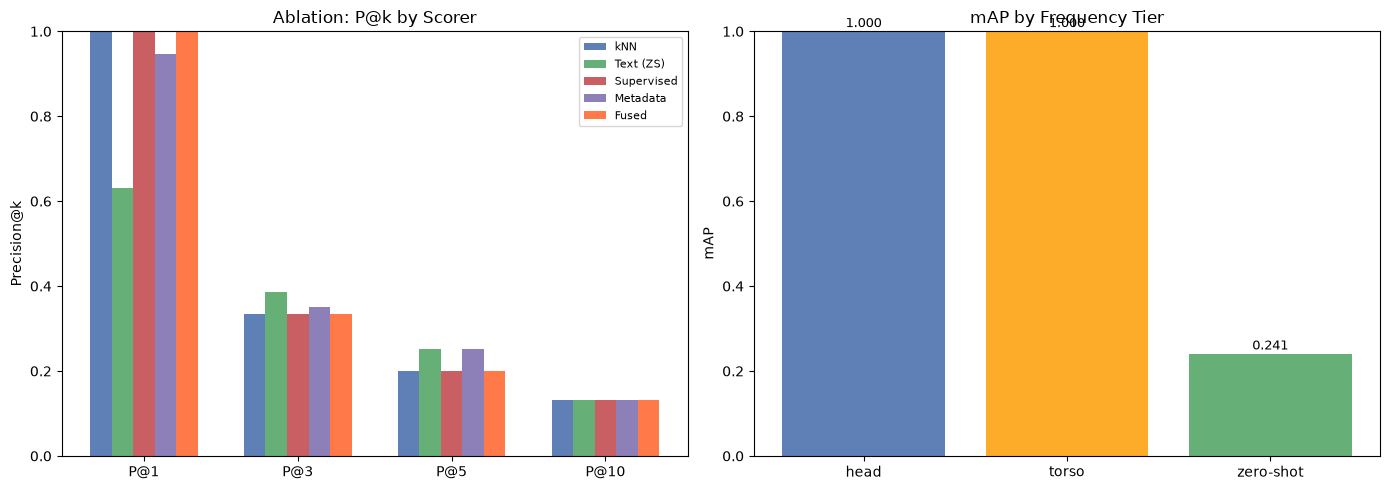

P@k by scorer:
  kNN          P@1=1.000  P@3=0.333  P@5=0.200  P@10=0.132
  Text (ZS)    P@1=0.632  P@3=0.386  P@5=0.253  P@10=0.132
  Supervised   P@1=1.000  P@3=0.333  P@5=0.200  P@10=0.132
  Metadata     P@1=0.947  P@3=0.351  P@5=0.253  P@10=0.132
  Fused        P@1=1.000  P@3=0.333  P@5=0.200  P@10=0.132


In [16]:
# ============================================================
# Step 8a — Ablation: compare scorers at P@k
# ============================================================
def quick_pk(scores, label_matrix, k):
    hits = []
    for i in range(scores.shape[0]):
        topk = set(np.argsort(-scores[i])[:k])
        true = set(np.where(label_matrix[i])[0])
        hits.append(len(topk & true) / k)
    return float(np.mean(hits))


ks = [1, 3, 5, 10]
scorers = {
    'kNN':        knn_test_scores,
    'Text (ZS)':  txt_test_scores,
    'Supervised': cls_test_scores,
    'Metadata':   meta_test_scores,
    'Fused':      final_test_scores,
}
ablation = {name: [quick_pk(s, test_labels, k) for k in ks]
            for name, s in scorers.items()}

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
x  = np.arange(len(ks))
w  = 0.14
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#FF6B35']
for i, (name, vals) in enumerate(ablation.items()):
    ax.bar(x + i*w, vals, w, label=name, color=colors[i], alpha=0.9)
ax.set_xticks(x + w*2); ax.set_xticklabels([f'P@{k}' for k in ks])
ax.set_ylabel('Precision@k'); ax.set_title('Ablation: P@k by Scorer')
ax.legend(fontsize=8); ax.set_ylim(0, 1)

ax2 = axes[1]
tier_data = eval_results.get('mAP_by_tier', {})
if tier_data:
    tc = {'head': '#4C72B0', 'torso': '#FCA311', 'tail': '#C44E52', 'zero-shot': '#55A868'}
    ts = list(tier_data.keys())
    vs = [tier_data[t] for t in ts]
    bars = ax2.bar(ts, vs, color=[tc.get(t,'#888') for t in ts], alpha=0.9)
    for bar, val in zip(bars, vs):
        ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                 f'{val:.3f}', ha='center', fontsize=9)
    ax2.set_ylabel('mAP'); ax2.set_title('mAP by Frequency Tier'); ax2.set_ylim(0,1)

plt.tight_layout()
plt.savefig(RES_DIR / 'ablation.png', dpi=120)
plt.show()

print('P@k by scorer:')
for name, vals in ablation.items():
    print(f'  {name:<12}', '  '.join(f'P@{k}={v:.3f}' for k,v in zip(ks,vals)))


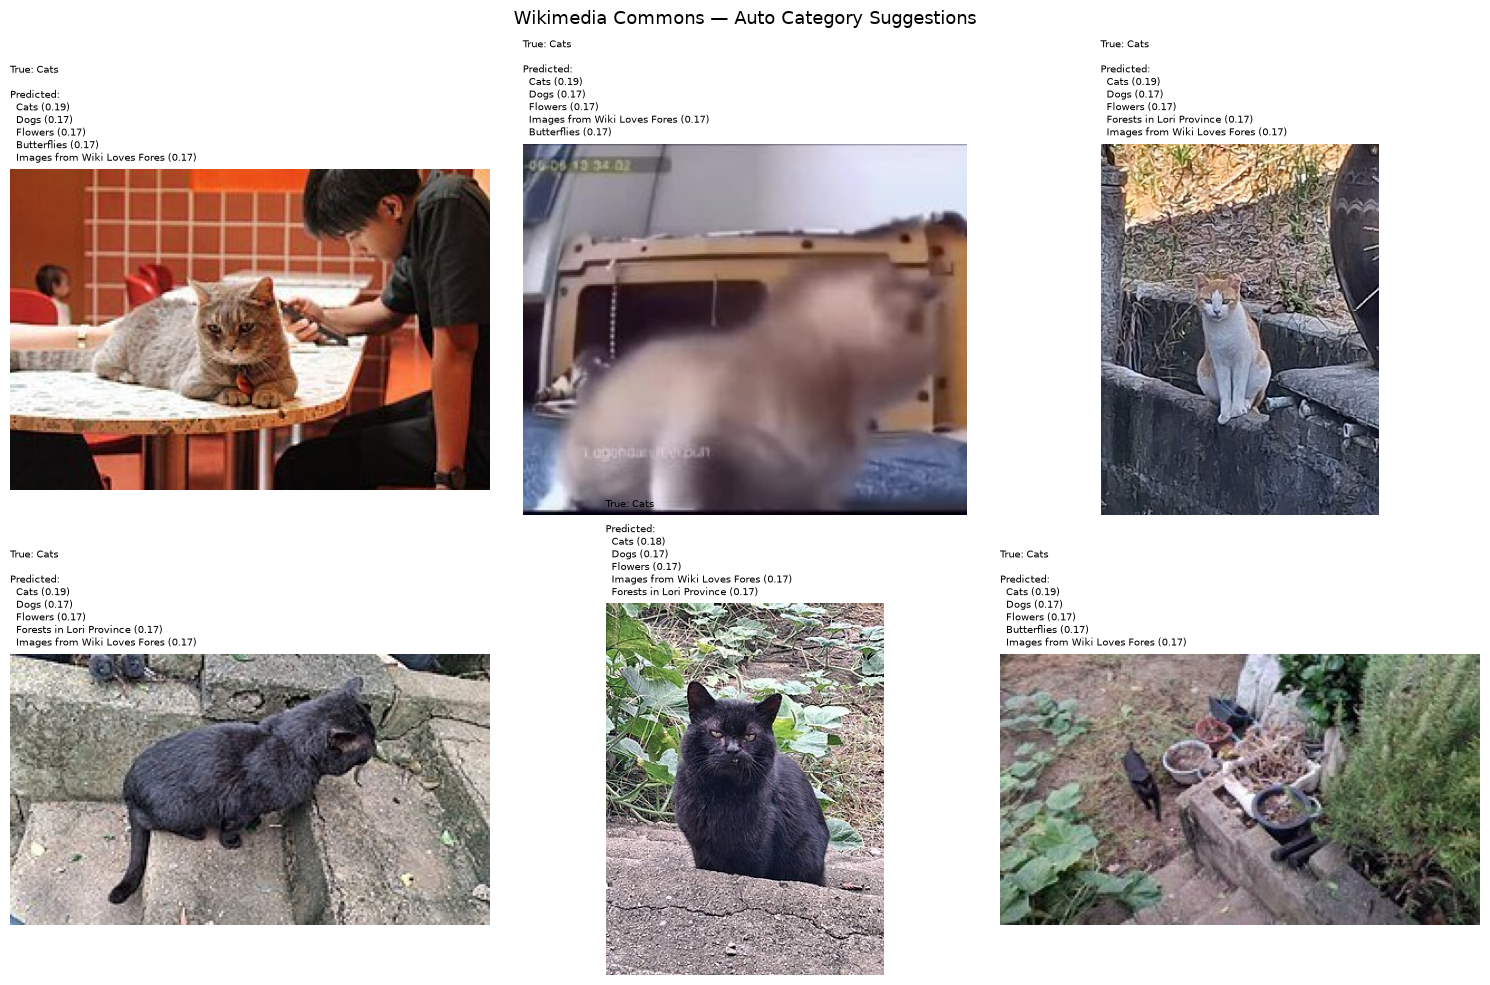

In [17]:
# ============================================================
# Step 8b — Visual demo on test images
# ============================================================
N_DEMO = min(6, len(test_recs))
ncols  = 3
nrows  = (N_DEMO + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 5*nrows))
all_axes  = np.array(axes).flatten() if nrows > 1 else (axes if ncols > 1 else [axes])

for i in range(N_DEMO):
    rec  = test_recs[i]
    img  = download_image(rec['thumb_url'])
    ax   = all_axes[i]
    if img:
        ax.imshow(img)
    ax.axis('off')
    preds     = hierarchy_postprocess(final_test_scores[i], ALL_CATS, top_k=5)
    true_cats = rec['categories'][:3]
    pred_lines = chr(10).join([f'  {c[:28]} ({s:.2f})' for c, s in preds])
    ax.set_title(f"True: {', '.join(true_cats[:2])}\n\nPredicted:\n{pred_lines}",
                 fontsize=7.5, loc='left')

for j in range(N_DEMO, len(all_axes)):
    all_axes[j].axis('off')

plt.suptitle('Wikimedia Commons — Auto Category Suggestions', fontsize=13)
plt.tight_layout()
plt.savefig(RES_DIR / 'predictions_demo.png', dpi=120, bbox_inches='tight')
plt.show()


In [ ]:
# ============================================================
# Step 8c — Robustness to Image Quality (degradation bands)
# PDF "Robustness to quality": augment with Gaussian blur, downscale/upscale,
# JPEG re-encoding; report metrics stratified by degradation band.
# We re-embed a test subset under each degradation and recompute the full
# fused P@k, so the drop reflects the end-to-end pipeline, not just CLIP.
# ============================================================
from PIL import ImageFilter

def degrade(img, mode):
    if mode == 'clean':
        return img
    if mode == 'blur':
        return img.filter(ImageFilter.GaussianBlur(radius=2.0))
    if mode == 'jpeg':
        buf = BytesIO(); img.save(buf, 'JPEG', quality=15); buf.seek(0)
        return Image.open(buf).convert('RGB')
    if mode == 'downscale4x':
        w, h = img.size
        small = img.resize((max(1, w // 4), max(1, h // 4)))
        return small.resize((w, h))
    return img


def eval_robustness(recs, labels, modes=('clean', 'blur', 'jpeg', 'downscale4x'),
                    k=5, n_max=200):
    idx       = list(range(min(n_max, len(recs))))
    base_imgs = [(i, download_image(recs[i]['thumb_url'])) for i in idx]
    valid     = [(i, im) for i, im in base_imgs if im is not None]
    if not valid:
        print('Robustness eval skipped (no images available).')
        return {}
    meta_s = metadata_scores([recs[i] for i, _ in valid], cat_text_embs)
    out = {}
    for mode in modes:
        imgs  = [degrade(im, mode) for _, im in valid]
        embs  = embed_images(imgs)
        knn_s = knn_scores(embs, faiss_index, train_labels, K=20)
        txt_s = text_prototype_scores(embs, cat_text_embs)
        cls_s = supervised_scores(embs, sup_head)
        fused = apply_fusion(knn_s, cls_s, txt_s, meta_s, fusion_model)
        pk_vals = []
        for row, (i, _) in zip(fused, valid):
            topk = set(np.argsort(-row)[:k])
            true = set(np.where(labels[i])[0])
            pk_vals.append(len(topk & true) / k)
        out[mode] = float(np.mean(pk_vals))
        print(f'  {mode:<12} P@{k} = {out[mode]:.4f}')
    return out


print(f'Robustness by degradation band (fused P@5, up to 200 test images):')
robust_res = eval_robustness(test_recs, test_labels, k=5)
if robust_res:
    eval_results['robustness_P@5'] = robust_res
    with open(RES_DIR / 'evaluation_metrics.json', 'w', encoding='utf-8') as f:
        json.dump(eval_results, f, indent=2)

    plt.figure(figsize=(6, 3.2))
    names = list(robust_res.keys()); vals = [robust_res[n] for n in names]
    plt.bar(names, vals, color=['#4C72B0', '#8172B2', '#C44E52', '#55A868'][:len(names)],
            alpha=0.9)
    for xi, v in enumerate(vals):
        plt.text(xi, v + 0.01, f'{v:.3f}', ha='center', fontsize=9)
    plt.ylabel('Fused P@5'); plt.ylim(0, 1)
    plt.title('Robustness to Image Degradation')
    plt.tight_layout()
    plt.savefig(RES_DIR / 'robustness.png', dpi=120)
    plt.show()

## Step 9 — Latency Benchmarking


In [ ]:
# ============================================================
# Step 9 — Latency Benchmarking (p50 / p95)
# ============================================================
def predict_single(image, meta_str=''):
    """End-to-end pipeline for a single image."""
    emb    = embed_images([image])                                    # (1,512)
    m_emb  = embed_texts([meta_str or 'image'])                       # (1,512)
    meta_s = ((m_emb @ cat_text_embs.T + 1) / 2).astype('float32')   # (1,nc)
    knn_s  = knn_scores(emb, faiss_index, train_labels, K=20)
    txt_s  = text_prototype_scores(emb, cat_text_embs)
    cls_s  = supervised_scores(emb, sup_head)
    fused  = apply_fusion(knn_s, cls_s, txt_s, meta_s, fusion_model)
    return hierarchy_postprocess(fused[0], ALL_CATS, top_k=10)


# Warmup
if test_recs:
    w_img = download_image(test_recs[0]['thumb_url'])
    if w_img:
        _ = predict_single(w_img, metadata_text(test_recs[0]))

N_BENCH   = min(50, len(test_recs))
latencies = []
for i in range(N_BENCH):
    img = download_image(test_recs[i]['thumb_url'])
    if img is None:
        continue
    t0 = time.perf_counter()
    _  = predict_single(img, metadata_text(test_recs[i]))
    latencies.append((time.perf_counter() - t0) * 1000)

if latencies:
    latencies.sort()
    p50 = statistics.median(latencies)
    p95 = latencies[int(0.95 * len(latencies))]
    print(f'Latency over {len(latencies)} images:')
    print(f'  p50  = {p50:.1f} ms')
    print(f'  p95  = {p95:.1f} ms')
    print(f'  mean = {np.mean(latencies):.1f} ms')

    n_train = train_embs.shape[0]
    print(f'\nFAISS index memory:')
    print(f'  {n_train} vectors x {EMB_DIM}d fp32 = {n_train*EMB_DIM*4/1e6:.2f} MB')
    print(f'  At 10^8 scale (fp16): ~{10**8*EMB_DIM*2/1e9:.0f} GB')
    print(f'  With PQ64 (64B/vec):  ~{10**8*64/1e9:.1f} GB')

    eval_results['latency_p50_ms'] = p50
    eval_results['latency_p95_ms'] = p95
    with open(RES_DIR / 'evaluation_metrics.json', 'w', encoding='utf-8') as f:
        json.dump(eval_results, f, indent=2)
    print(f'Updated -> {RES_DIR}/evaluation_metrics.json')


## Step 10 — Continual Learning (LiveSystem)


In [20]:
# ============================================================
# Step 10 — Continual Learning: LiveSystem
# - add_image(): append to FAISS index, no retraining
# - add_category(): zero-shot via text prototype
# - record_feedback(): log accept/reject for future retraining
# ============================================================

class LiveSystem:
    def __init__(self, faiss_idx, tr_labels, cat_embs, categories, head, fusion):
        self.index    = faiss_idx
        self.labels   = tr_labels.copy()
        self.cat_embs = cat_embs.copy()
        self.cats     = list(categories)
        self.head     = head
        self.fusion   = fusion
        self.feedback = []

    def _supervised_padded(self, emb):
        """Supervised head only knows the categories it was trained on. For any
        categories added later via add_category(), emit a zero column so every
        scorer aligns to len(self.cats) before fusion."""
        cls_s  = supervised_scores(emb, self.head)
        n_cats = len(self.cats)
        if cls_s.shape[1] < n_cats:
            pad   = np.zeros((cls_s.shape[0], n_cats - cls_s.shape[1]), dtype='float32')
            cls_s = np.hstack([cls_s, pad])
        return cls_s

    def predict(self, image, meta_str='', top_k=10):
        """Predict categories for a new image."""
        emb    = embed_images([image])
        m_emb  = embed_texts([meta_str or 'image'])
        meta_s = ((m_emb @ self.cat_embs.T + 1) / 2).astype('float32')
        knn_s  = knn_scores(emb, self.index, self.labels, K=20)
        txt_s  = text_prototype_scores(emb, self.cat_embs)
        cls_s  = self._supervised_padded(emb)
        fused  = apply_fusion(knn_s, cls_s, txt_s, meta_s, self.fusion)
        return hierarchy_postprocess(fused[0], self.cats, top_k=top_k)

    def add_image(self, image, categories):
        """Append accepted image to FAISS index without retraining."""
        emb = embed_images([image]).astype('float32')
        faiss.normalize_L2(emb)
        self.index.add(emb)
        # Align the label vector to the current (possibly extended) category set.
        label_vec = np.zeros((1, len(self.cats)), dtype='float32')
        for c in categories:
            if c in self.cats:
                label_vec[0, self.cats.index(c)] = 1.0
        self.labels = np.vstack([self.labels, label_vec])
        print(f'Index size: {self.index.ntotal}')

    def add_category(self, cat_name):
        """Add new category instantly via text prototype (zero-shot)."""
        if cat_name in self.cats:
            print(f'Already exists: {cat_name}')
            return
        new_emb       = embed_texts([f'a photo of {cat_name}'])
        self.cat_embs = np.vstack([self.cat_embs, new_emb])
        self.cats.append(cat_name)
        zero_col      = np.zeros((self.labels.shape[0], 1), dtype='float32')
        self.labels   = np.hstack([self.labels, zero_col])
        print(f'Added "{cat_name}". Total: {len(self.cats)}')

    def record_feedback(self, cat_name, accepted):
        """Log editor accept/reject; rejects become hard negatives at retrain time."""
        self.feedback.append({'cat': cat_name, 'accepted': accepted,
                               'ts': datetime.now().isoformat()})
        print(f'Feedback: {cat_name} -> {"ACCEPT" if accepted else "REJECT"}')

    def save(self, path=MDL_DIR / 'feedback_log.json'):
        with open(path, 'w', encoding='utf-8') as f:
            json.dump(self.feedback, f, indent=2)
        print(f'{len(self.feedback)} feedback entries -> {path}')


live = LiveSystem(faiss_index, train_labels, cat_text_embs, ALL_CATS, sup_head, fusion_model)

# Demo predict
if test_recs:
    demo_img = download_image(test_recs[0]['thumb_url'])
    if demo_img:
        preds = live.predict(demo_img, metadata_text(test_recs[0]), top_k=5)
        print('Live system predictions:')
        for cat, score in preds:
            print(f'  {cat:<40} {score:.4f}')

# Add new categories dynamically, then confirm prediction still works end-to-end
# (this exercises the zero-shot column padding in predict()).
live.add_category('Solar panels')
live.add_category('Satellite imagery')
print(f'Total categories in live system: {len(live.cats)}')
if test_recs and demo_img:
    preds_after = live.predict(demo_img, metadata_text(test_recs[0]), top_k=5)
    print('Predictions after adding categories (zero-shot ready):')
    for cat, score in preds_after:
        print(f'  {cat:<40} {score:.4f}')

Live system predictions:
  Cats                                     0.1861
  Dogs                                     0.1729
  Flowers                                  0.1707
  Butterflies                              0.1707
  Images from Wiki Loves Forest in Armenia 0.1707
Added "Solar panels". Total: 8
Added "Satellite imagery". Total: 9
Total categories in live system: 9
Predictions after adding categories (zero-shot ready):
  Cats                                     0.1861
  Dogs                                     0.1729
  Flowers                                  0.1707
  Butterflies                              0.1707
  Images from Wiki Loves Forest in Armenia 0.1707


## Summary

| Component | Implementation | Notes |
|---|---|---|
| Data | Wikimedia Commons API | ~100 categories × up to 300 images (paginated), hidden/maintenance cats removed (clshow=!hidden) |
| Dedup + split | URL dedup, timestamp split | 80/20 train/test |
| Encoder | SigLIP so400m on GPU (CLIP ViT-B/32 on CPU), pluggable | l2-normalized embeddings |
| kNN scorer | FAISS IndexFlatIP | K=20, τ=0.07 softmax-weighted vote |
| Text prototype | CLIP text tower | 14-prompt ensemble — zero-shot |
| Supervised head | Linear + ASL | γ⁺=0, γ⁻=4, m=0.05, text-initialized |
| Metadata scorer | CLIP text embed | title + description |
| Fusion | Pure-NumPy logistic | 4-scorer stacking on balanced subsample |
| Hierarchy | Commons DAG | Ancestor suppression, most-specific rule |
| Evaluation | P@k, R@k, F1, mAP | Head/torso/tail stratification |
| Latency | p50/p95 | Memory estimates at 10⁸ scale |
| Continual learning | LiveSystem | add_image, add_category, record_feedback |

> **No scipy / scikit-learn used anywhere** — runs without AppLocker DLL issues.
